# Example 02: Spread between ground-motion models

Each model gives a median and a standard deviation. The difference between the medians of different models is a measure of the epistemic uncertainty, and is separate from the aleatory variability that the standard deviation of each model describes. This example computes both for the five NGA-West2 models, with the 1 s spectral acceleration as a function of distance and with the full spectrum.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import pygmm

%matplotlib inline

In [2]:
scenario = pygmm.Scenario(
    mag=6.5,
    dist_rup=20.0,
    dist_jb=20.0,
    dist_x=20.0,
    dip=90.0,
    mechanism="SS",
    v_s30=760.0,
)

classes = [
    pygmm.AbrahamsonSilvaKamai2014,
    pygmm.BooreStewartSeyhanAtkinson2014,
    pygmm.CampbellBozorgnia2014,
    pygmm.ChiouYoungs2014,
    pygmm.Idriss2014,
]
periods = np.geomspace(0.02, 10.0, 60)


def ln_sa_and_std(scenario):
    """Natural log of the median SA and its standard deviation for each model."""
    models = [cls(scenario) for cls in classes]
    ln_sa = np.array([np.log(m.interp_spec_accels(periods)) for m in models])
    ln_std = np.array([m.interp_ln_stds(periods) for m in models])
    return ln_sa, ln_std


ln_sa, ln_std = ln_sa_and_std(scenario)
between = ln_sa.std(axis=0, ddof=1)  # standard deviation of the medians
within = np.sqrt((ln_std**2).mean(axis=0))  # root-mean-square of the sigmas

## Medians relative to the mean

The ratio of each median to the geometric mean of the five, and the between-model and within-model standard deviations of $\ln$ SA.

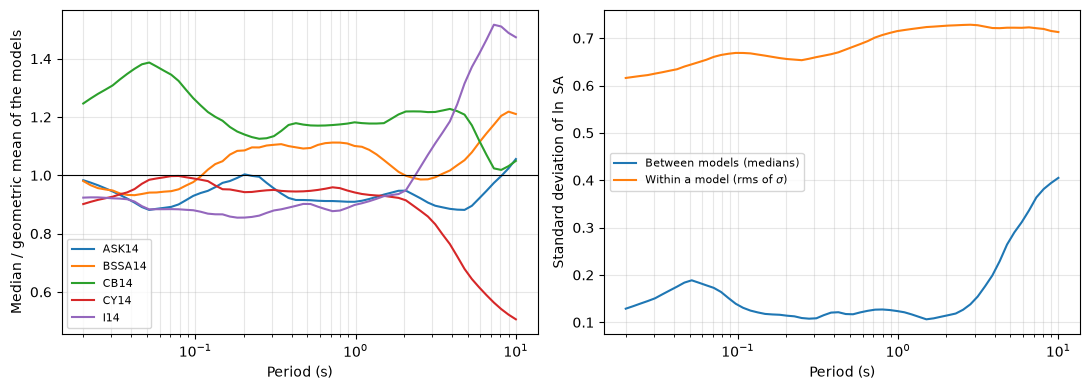

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for cls, row in zip(classes, ln_sa):
    axes[0].plot(periods, np.exp(row - ln_sa.mean(axis=0)), label=cls.ABBREV)
axes[0].axhline(1.0, color="k", lw=0.8)
axes[0].set(xscale="log", ylabel="Median / geometric mean of the models")
axes[1].plot(periods, between, label="Between models (medians)")
axes[1].plot(periods, within, label="Within a model (rms of $\\sigma$)")
axes[1].set(xscale="log", ylabel="Standard deviation of $\\ln$ SA")
for ax in axes:
    ax.set_xlabel("Period (s)")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()

## Spread with distance

The same two measures at 1 s, from 1 to 150 km.

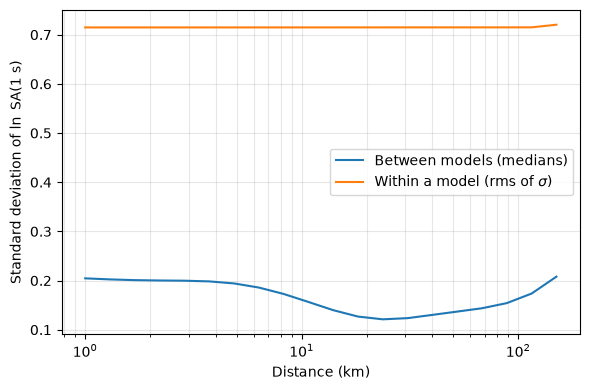

In [4]:
dists = np.geomspace(1.0, 150.0, 20)
i1 = np.argmin(np.abs(periods - 1.0))
spread = []
for r in dists:
    ln_sa_r, ln_std_r = ln_sa_and_std(
        scenario.copy_with(dist_rup=r, dist_jb=r, dist_x=r)
    )
    spread.append((ln_sa_r[:, i1].std(ddof=1), np.sqrt((ln_std_r[:, i1] ** 2).mean())))
spread = np.array(spread)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(dists, spread[:, 0], label="Between models (medians)")
ax.plot(dists, spread[:, 1], label="Within a model (rms of $\\sigma$)")
ax.set(
    xscale="log", xlabel="Distance (km)", ylabel="Standard deviation of $\\ln$ SA(1 s)"
)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()

### Observations

- **The median spread is smaller than the standard deviation of each model**: the standard deviation of the medians is 0.11 to 0.19 in $\ln$ units for periods up to 3 s, against 0.62 to 0.73 within the models.
- **It increases at long periods**, to 0.4 at 10 s, where Chiou and Youngs (2014) falls to half of the geometric mean of the models and Idriss (2014) rises to 1.5 times it.
- **At short periods** Campbell and Bozorgnia (2014) is 25 to 40% above the geometric mean for periods shorter than 0.1 s.
- **With distance** the spread of the medians at 1 s is between 0.12 and 0.21 and is the smallest near 25 km; the standard deviation of the models, 0.72, hardly changes.